# Daily land area with precipitation > 1 mm vs. land warming, 30–60°N: CMIP6 models (2021–2049)

Same figure as `cesm2_ens_land_daily_temp_histo_fut.ipynb`, with CESM2 replaced by the CMIP6 models, using the first member of each model (`MEMBERS_PER_MODEL = 1`; lowest r, then i, p, f, the same member as in the other CMIP6 notebooks).

- **Data:** the ssp370 per-member files of `cmip6_precip_cover_calc.py` (daily % of land area at 30–60°N with precipitation > 1 mm/day, May–Oct), and annual `tas` from cmip6-ng. For tas, land is `sftlf > 0` with cos(lat) area weights. BCC-CSM2-MR has no sftlf file and uses the `FALLBACK_MASK_MODEL` mask.
- **Lines:** one KDE line per model per year (2021–2049), so every model has the same number of lines. Each line is the distribution of the member's ~184 daily values in that year (with `MEMBERS_PER_MODEL` > 1, the members of a year are pooled, as the CESM2 original did). It is coloured by the model's temperature change over land at 30–60°N relative to 2021.
- **KDE:** Gaussian KDE with Scott's bandwidth, as in `sns.kdeplot(bw_adjust=1)`, computed directly for speed.
- **Regression (per model):** x is the raw annual land-mean temperature (30–60°N) of the model's member, as in the CESM2 and IFS notebooks. y is the yearly mean wet-land percentage over the member's days. Year-to-year temperature variability in x lowers the slope compared with a trend-smoothed x (regression dilution). The table gives slope (percentage points per °C), R² and p-value per model, and the CMIP6 mean is the average of the model values.

In [27]:
import os
import re
from collections import defaultdict

import numpy as np
import pandas as pd
import xarray as xr
from scipy import stats
import matplotlib.pyplot as plt
from matplotlib.collections import LineCollection
import seaborn as sns
import warnings
warnings.filterwarnings(action='ignore')

In [28]:
# ── settings ─────────────────────────────────────────────────────────────────
PC_DIR        = '/home/jwille/xenon_data/NextGEMS/mid_lat_precip/CMIP6'   # precip_cover_<model>_ssp370_<member>_30-60N.nc
TAS_DIR       = '/net/atmos/data/cmip6-ng/tas/ann/native'
SFTLF_DIR     = '/net/atmos/data/cmip6-ng/sftlf/fx/native'
EXPERIMENT    = 'ssp370'
THRESHOLD     = 1.0                     # mm/day
YEARS         = (2021, 2049)
REF_YEAR      = 2021
latitude      = [30, 60]

FALLBACK_MASK_MODEL = 'MPI-ESM1-2-HR'   # mask used for models without an sftlf file (BCC-CSM2-MR)
EXCLUDE_MODELS      = []                # e.g. ['BCC-CSM2-MR']
MEMBERS_PER_MODEL   = 1                 # first N members of each model (sorted r, i, p, f); None = all members

CBAR_RANGE     = (-0.1, 2.4)            # colour-bar limits (°C); None = 1st-99th percentile of the data
LINE_WIDTH     = 1.5                    # CESM2 original: 2.0 (with 29 lines; here 29 per model)

# KDE evaluation grid and plot range (as in the original)
xmin, xmax = 10, 60
bin_width  = 1.0
X_GRID     = np.linspace(xmin, xmax, 401)

OUT_FIG        = '/home/jwille/images/global_paper/mid_lat_land_cmip6_ens_histo_precip_coverage_daily_1_temp.pdf'
OUT_TABLE      = '/home/jwille/images/global_paper/mid_lat_land_cmip6_precip_coverage_daily_1_temp_regression.csv'
OUT_FIG_PANELS = '/home/jwille/images/global_paper/mid_lat_land_cmip6_ens_histo_precip_coverage_daily_1_temp_per_model.pdf'
PANEL_COLS     = 5                      # panels per row in the per-model figure

In [29]:
PC_NAME  = re.compile(r'^precip_cover_(?P<model>[^_]+)_(?P<exp>[^_]+)_(?P<member>r\d+i\d+p\d+f\d+)_[^_]+\.nc$')
TAS_NAME = re.compile(r'^tas_ann_(?P<model>[^_]+)_(?P<exp>[^_]+)_(?P<member>r\d+i\d+p\d+f\d+)_[^_]+\.nc$')


def member_sort_key(member):
    return [int(n) for n in re.findall(r'\d+', member)]


def nearest_regrid(src, lat, lon):
    """Nearest-neighbour match of a lat/lon field to the given lat/lon (lon periodic).
    Identical grids give exactly the original values."""
    ilat = np.abs(src.lat.values[:, None] - np.asarray(lat)[None, :]).argmin(axis=0)
    dlon = (src.lon.values[:, None] - np.asarray(lon)[None, :] + 180) % 360 - 180
    ilon = np.abs(dlon).argmin(axis=0)
    return xr.DataArray(src.values[np.ix_(ilat, ilon)], dims=('lat', 'lon'), coords={'lat': lat, 'lon': lon})


def find_sftlf(model):
    """sftlf file of a model: historical preferred, else any experiment; None if there is none."""
    pat = re.compile(rf'^sftlf_fx_{re.escape(model)}_(?P<exp>[^_]+)_(?P<mem>[^_]+)_[^_]+\.nc$')
    cands = [(m['exp'] != 'historical', member_sort_key(m['mem']), f)
             for f in os.listdir(SFTLF_DIR) if (m := pat.match(f))]
    return os.path.join(SFTLF_DIR, sorted(cands)[0][2]) if cands else None


def land_mask(model, lat, lon):
    path = find_sftlf(model)
    src = xr.open_dataset(path or find_sftlf(FALLBACK_MASK_MODEL))['sftlf'].load()
    return (nearest_regrid(src, lat, lon) > 0).values, (os.path.basename(path) if path else f'{FALLBACK_MASK_MODEL} (fallback)')


def land_mean_tas(model, path):
    """Annual tas, cos(lat)-weighted mean over land at 30-60N, as a Series indexed by year."""
    tas = xr.open_dataset(path)['tas'].load()
    tas = tas.assign_coords(time=tas.time.dt.year).rename(time='year').sel(year=slice(*YEARS))
    tas = tas.isel(lat=np.where((tas.lat.values >= latitude[0]) & (tas.lat.values <= latitude[1]))[0])
    land, _ = land_mask(model, tas.lat.values, tas.lon.values)
    w = np.cos(np.deg2rad(tas.lat.values))[:, None] * np.ones(tas.sizes['lon'])
    return pd.Series([np.average(tas.sel(year=y).values[land], weights=w[land]) for y in tas.year.values],
                     index=tas.year.values)

In [30]:
# ── per-member daily wet-land % and land temperature; one pooled KDE line per model and year ──
pc_files = defaultdict(list)
for f in os.listdir(PC_DIR):
    if (m := PC_NAME.match(f)) and m['exp'] == EXPERIMENT and m['model'] not in EXCLUDE_MODELS:
        pc_files[m['model']].append((m['member'], f))
tas_files = {(m['model'], m['member']): f for f in os.listdir(TAS_DIR)
             if (m := TAS_NAME.match(f)) and m['exp'] == EXPERIMENT}

lines = []        # one dict per model and year: curve, dT
per_model = {}    # model -> yearly mean wet-land % and land-mean temperature, DataFrames (year x member)

for model in sorted(pc_files, key=str.lower):
    pc_mean, tas_mean, pooled = {}, {}, defaultdict(list)    # pooled: year -> daily values of all members
    members = sorted(pc_files[model], key=lambda mf: member_sort_key(mf[0]))
    for mem, _ in members:
        if (model, mem) not in tas_files:
            print(f'{model} {mem}: no tas file, member skipped')
    members = [mf for mf in members if (model, mf[0]) in tas_files][:MEMBERS_PER_MODEL]   # first member(s) only
    for mem, fname in members:
        da = xr.open_dataset(os.path.join(PC_DIR, fname), use_cftime=True)['wet_land_pct']
        da = da.sel(threshold=THRESHOLD, method='nearest')
        if abs(float(da.threshold) - THRESHOLD) > 1e-9:
            raise ValueError(f'{fname}: no threshold {THRESHOLD} mm/day')
        yr = da.time.dt.year.values
        vals = da.values
        keep = (yr >= YEARS[0]) & (yr <= YEARS[1]) & np.isfinite(vals)
        s = pd.Series(vals[keep]).groupby(yr[keep])
        pc_mean[mem] = s.mean()
        for y, v in s:
            pooled[int(y)].append(v.values)
        tas_mean[mem] = land_mean_tas(model, os.path.join(TAS_DIR, tas_files[(model, mem)]))

    if not pc_mean:
        continue
    pc_df, tas_df = pd.DataFrame(pc_mean), pd.DataFrame(tas_mean)
    per_model[model] = dict(pc=pc_df, tas=tas_df, n_members=pc_df.shape[1])
    ens_dT = tas_df.mean(axis=1) - tas_df.mean(axis=1).loc[REF_YEAR]      # ensemble-mean land warming
    for y, vs in sorted(pooled.items()):
        if y not in ens_dT.index:
            continue
        v = np.concatenate(vs)                                            # all members of this year pooled
        curve = stats.gaussian_kde(v)(X_GRID) if np.ptp(v) > 0 else np.zeros_like(X_GRID)
        lines.append(dict(model=model, year=y, dT=float(ens_dT.loc[y]), curve=curve))
    print(f'{model:14s} {", ".join(pc_df.columns)}, {pc_df.shape[0]} years')

print(f'\n{len(lines)} lines from {len(per_model)} models')

ACCESS-ESM1-5  r1i1p1f1, 29 years
BCC-CSM2-MR    r1i1p1f1, 29 years
CAMS-CSM1-0    r2i1p1f1, 29 years
CanESM5        r1i1p2f1, 29 years
CESM2          r1i1p1f1, 29 years
CNRM-ESM2-1    r1i1p1f2, 29 years
EC-Earth3      r1i1p1f1, 29 years
FGOALS-g3      r1i1p1f1, 29 years
GFDL-ESM4      r1i1p1f1, 29 years
INM-CM5-0      r1i1p1f1, 29 years
IPSL-CM6A-LR   r1i1p1f1, 29 years
MIROC6         r1i1p1f1, 29 years
MPI-ESM1-2-HR  r1i1p1f1, 29 years
MRI-ESM2-0     r1i1p1f1, 29 years
UKESM1-0-LL    r1i1p1f2, 29 years

435 lines from 15 models


In [31]:
# ── linear regression per model: wet-land % vs raw annual land temperature ──
rows = []
for model, d in per_model.items():
    x = d['tas'].mean(axis=1)          # annual land-mean temperature (mean over the members used)
    y = d['pc'].mean(axis=1)           # yearly mean wet-land % over the members' days
    x, y = x.align(y, join='inner')
    r = stats.linregress(x.values, y.values)   # raw annual values, as in the CESM2 and IFS notebooks
    rows.append(dict(model=model, members=d['n_members'], years=len(x),
                     slope=r.slope, r_squared=r.rvalue ** 2, p_value=r.pvalue))

regression = pd.DataFrame(rows).set_index('model')
regression.loc['CMIP6 mean'] = regression[['slope', 'r_squared', 'p_value']].mean()
regression.loc['CMIP6 mean', ['members', 'years']] = [regression['members'].iloc[:-1].sum(), np.nan]
os.makedirs(os.path.dirname(OUT_TABLE), exist_ok=True)
regression.to_csv(OUT_TABLE)
print(f"slope in percentage points per °C; {(regression['p_value'].iloc[:-1] < 0.05).sum()} of {len(regression) - 1} models have p < 0.05")
regression.style.format({'slope': '{:.3f}', 'r_squared': '{:.3f}', 'p_value': '{:.2e}', 'members': '{:.0f}', 'years': '{:.0f}'})

slope in percentage points per °C; 6 of 15 models have p < 0.05


,members,years,slope,r_squared,p_value
model,,,,,
ACCESS-ESM1-5,1,29,-0.618,0.060,2.01e-01
BCC-CSM2-MR,1,29,-0.546,0.189,1.83e-02
CAMS-CSM1-0,1,29,-0.270,0.036,3.27e-01
CanESM5,1,29,0.212,0.031,3.58e-01
CESM2,1,29,-0.633,0.216,1.12e-02
CNRM-ESM2-1,1,29,-0.884,0.402,2.24e-04
EC-Earth3,1,29,-0.027,0.000,9.54e-01
FGOALS-g3,1,29,0.131,0.016,5.13e-01
GFDL-ESM4,1,29,-1.205,0.267,4.09e-03


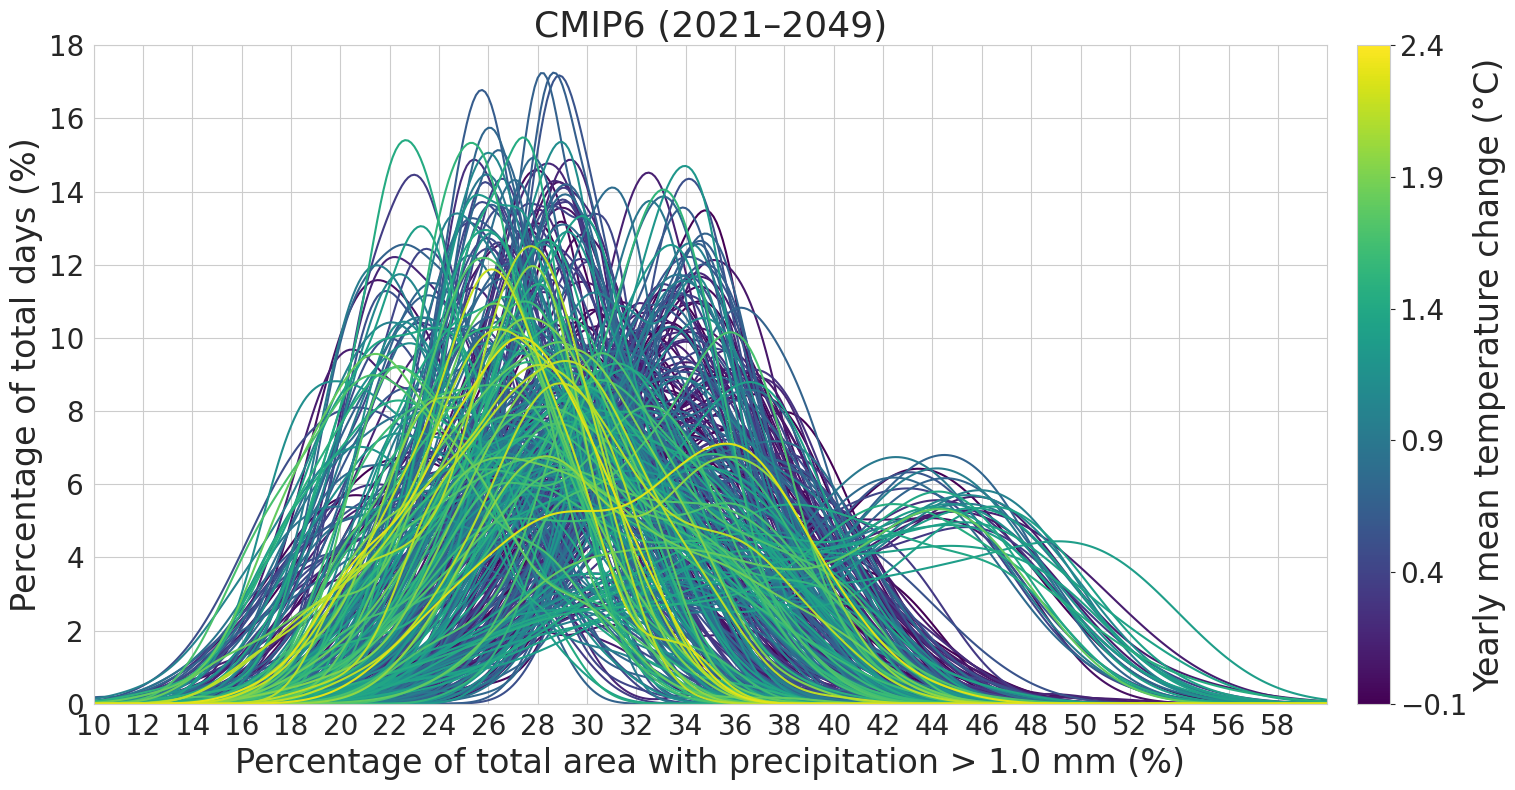

In [32]:
# ── plot: one line per model per year, coloured by the model's ensemble-mean land warming since REF_YEAR ──
dT_all = np.array([l['dT'] for l in lines])
vmin, vmax = CBAR_RANGE if CBAR_RANGE is not None else np.round(np.percentile(dT_all, [1, 99]), 1)
cmap = plt.get_cmap('viridis')
norm = plt.Normalize(vmin=vmin, vmax=vmax)

order = np.argsort(dT_all)                     # warmest lines drawn last (on top)
curves = np.array([lines[i]['curve'] for i in order]) * bin_width * 100   # density -> % of days per bin_width bin
segments = [np.column_stack([X_GRID, c]) for c in curves]

fig, ax = plt.subplots(figsize=(16, 8))
sns.set_style("whitegrid")
lc = LineCollection(segments, colors=cmap(norm(dT_all[order])), linewidths=LINE_WIDTH)
ax.add_collection(lc)

sm = plt.cm.ScalarMappable(cmap=cmap, norm=norm)
sm.set_array([])
cbar = fig.colorbar(sm, ax=ax, pad=0.02, ticks=np.linspace(vmin, vmax, 6))
cbar.set_label('Yearly mean temperature change (°C)', fontsize=24)
cbar.ax.tick_params(labelsize=20)

ax.set_xticks(np.arange(xmin, xmax, 2))
ax.set_ylim(0, 18)
ax.set_xlim(xmin, xmax)
ax.set_xlabel(f'Percentage of total area with precipitation > {THRESHOLD} mm (%)', fontsize=24)
ax.set_ylabel('Percentage of total days (%)', fontsize=24)
ax.tick_params(axis='both', which='major', labelsize=20)
ax.set_title(f'CMIP6 ({YEARS[0]}–{YEARS[1]})', fontsize=26)
plt.tight_layout()
os.makedirs(os.path.dirname(OUT_FIG), exist_ok=True)
plt.savefig(OUT_FIG, format='pdf', bbox_inches='tight')
plt.show()

## Per-model panels

One panel per model with its yearly lines, using the same colours, colour scale and axes as the figure above. Each panel shows the model's regression slope β₁ (percentage points per °C, raw annual temperature) and R² from the table; R² is bold when p < 0.05.

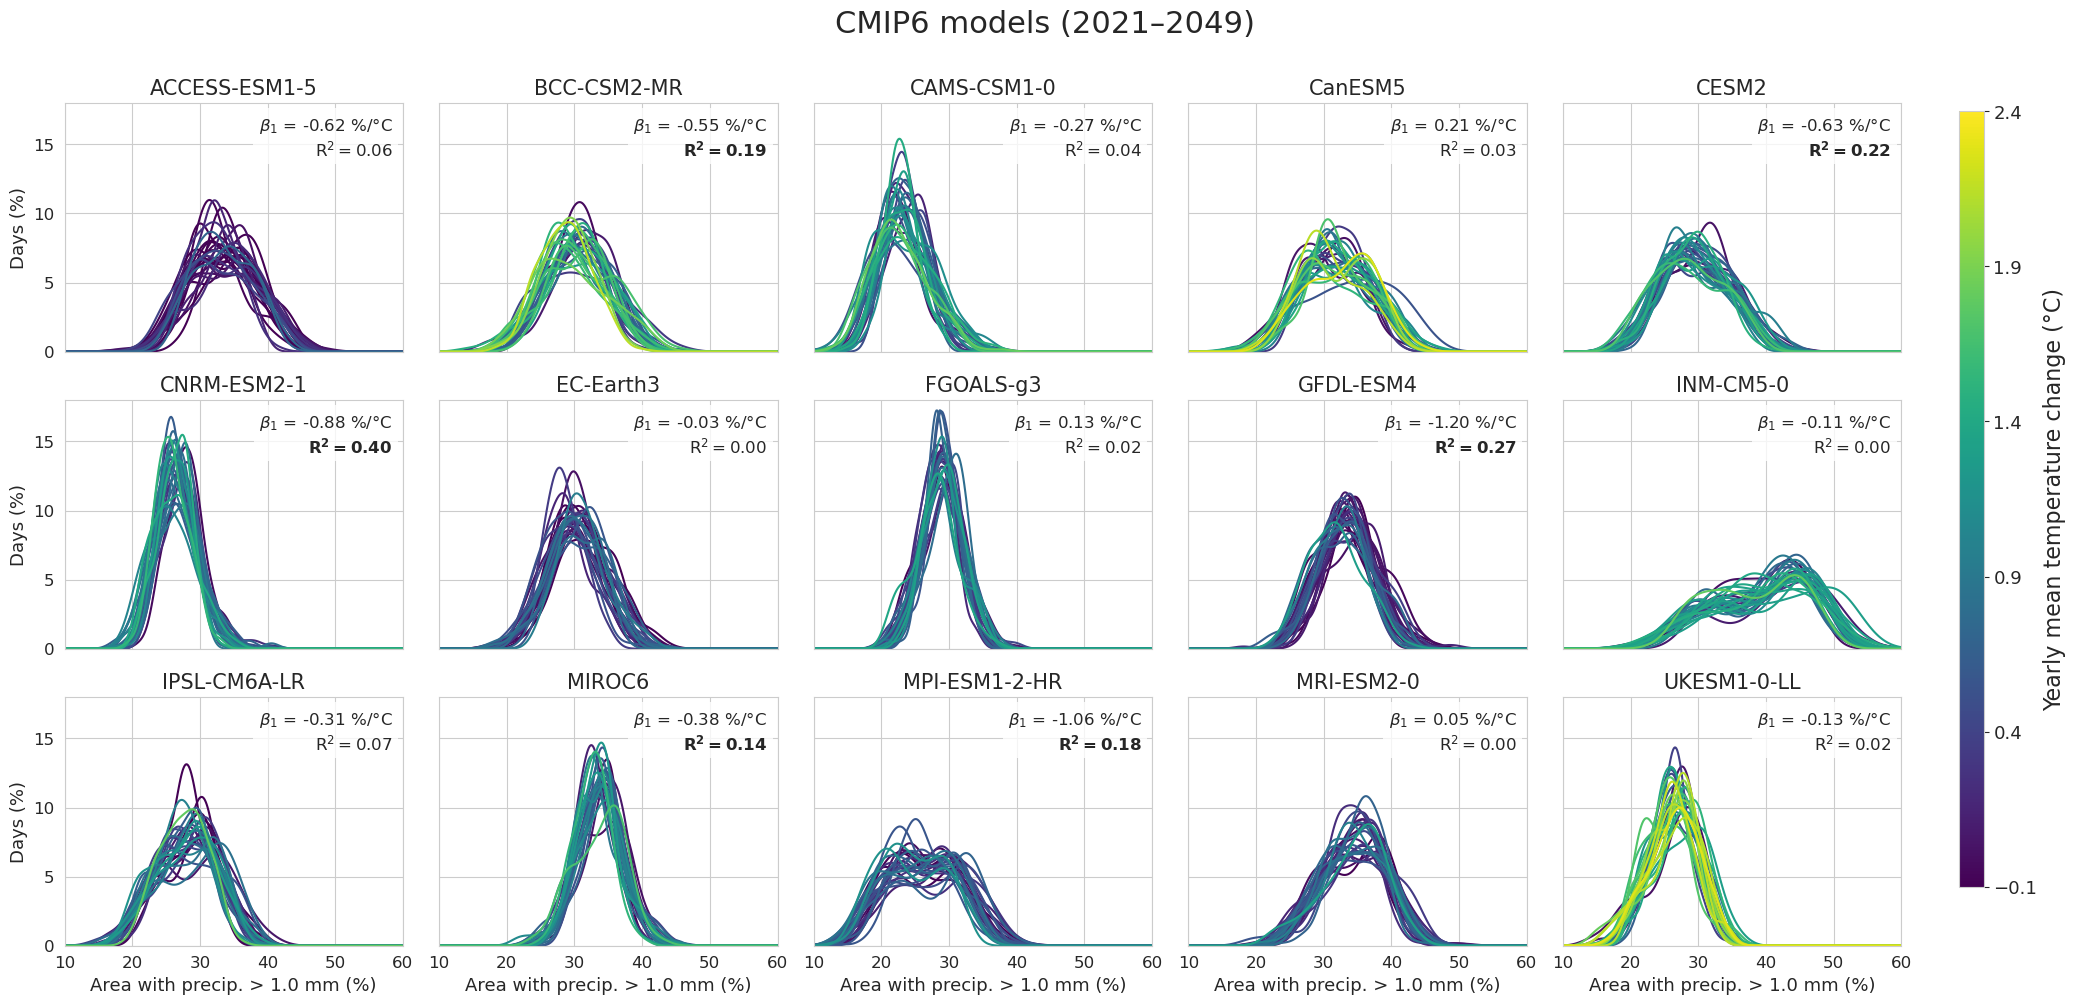

In [33]:
# ── one panel per model: its yearly lines, same colours and scale as the combined figure ──
models_plot = list(per_model)
n_rows = int(np.ceil(len(models_plot) / PANEL_COLS))
fig, axes = plt.subplots(n_rows, PANEL_COLS, figsize=(4.2 * PANEL_COLS, 3.4 * n_rows),
                         sharex=True, sharey=True, squeeze=False)
sns.set_style("whitegrid")

for ax, model in zip(axes.flat, models_plot):
    ml = sorted((l for l in lines if l['model'] == model), key=lambda l: l['dT'])   # warmest on top
    segs = [np.column_stack([X_GRID, l['curve'] * bin_width * 100]) for l in ml]
    ax.add_collection(LineCollection(segs, colors=cmap(norm([l['dT'] for l in ml])), linewidths=LINE_WIDTH))
    r = regression.loc[model]
    n_mem = per_model[model]['n_members']
    ax.set_title(model if n_mem == 1 else f"{model} ({n_mem})", fontsize=15)   # (n) only if several members
    # beta1 = slope; R² in bold when the regression is significant (p < 0.05)
    r2_txt = (r'$\mathbf{R^2 = %.2f}$' if r['p_value'] < 0.05 else r'$\mathrm{R^2 = %.2f}$') % r['r_squared']
    ax.text(0.97, 0.95, rf"$\beta_1$ = {r['slope']:.2f} %/°C" + '\n' + r2_txt,
            transform=ax.transAxes, ha='right', va='top', fontsize=12,
            bbox=dict(facecolor='white', edgecolor='none', alpha=0.8))
    ax.set_xlim(xmin, xmax)
    ax.set_ylim(0, 18)
    ax.set_xticks(np.arange(xmin, xmax + 1, 10))
    ax.tick_params(labelsize=12)

for ax in axes.flat[len(models_plot):]:          # hide unused panels
    ax.set_visible(False)
for ax in axes[-1, :]:
    ax.set_xlabel(f'Area with precip. > {THRESHOLD} mm (%)', fontsize=13)
for ax in axes[:, 0]:
    ax.set_ylabel('Days (%)', fontsize=13)

fig.suptitle(f'CMIP6 models ({YEARS[0]}–{YEARS[1]})', fontsize=22)
fig.tight_layout(rect=(0, 0, 0.92, 0.97))
cax = fig.add_axes([0.935, 0.12, 0.012, 0.76])
sm = plt.cm.ScalarMappable(cmap=cmap, norm=norm)
sm.set_array([])
cbar = fig.colorbar(sm, cax=cax, ticks=np.linspace(norm.vmin, norm.vmax, 6))
cbar.set_label('Yearly mean temperature change (°C)', fontsize=16)
cbar.ax.tick_params(labelsize=13)

os.makedirs(os.path.dirname(OUT_FIG_PANELS), exist_ok=True)
plt.savefig(OUT_FIG_PANELS, format='pdf', bbox_inches='tight')
plt.show()